# Human review 2: regional dataset for lead times of 1 to 12 weeks
An experimental dataset was built with NOAA-20 as reference, harmonized
history and past weather. No model has been trained or published yet.
The desired target is a new fire; the available label is a new
detected episode. No confirmed physical ignitions are claimed.

In [1]:
from pathlib import Path
import json
from IPython.display import display, Markdown, Image
import matplotlib.pyplot as plt

repo=next(p for p in [Path.cwd(),*Path.cwd().parents]
          if (p/'reports/prediction/dataset_manifest.json').exists())
folder=repo/'reports/prediction'
load=lambda name:json.loads((folder/name).read_text(encoding='utf-8'))
data=load('dataset_manifest.json')
protocol=load('evaluation_protocol.json')
nrt=load('nrt_ingestion_report.json')
reference=load('noaa20_label_manifest.json')
evidence=load('onset_evidence_report.json')
assert not data['model_trained'] and not data['physical_ignition_labels_verified']
print('Filas:',data['rows'])
print('Departamentos/Callao:',data['regions'])
print('Anticipaciones:',data['leads'])
print('Variables:',len(data['features']))
print('Referencia:',reference['reference_platform'])

Filas: 115350
Departamentos/Callao: 25
Anticipaciones: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
Variables: 32
Referencia: NOAA-20; single reference, no increase from adding platforms


## 1. Temporal split and label maturity
Each row identifies a region, a Sunday issue and a later target week.
Target weeks must end before the next period: it is not enough for
the issue date to fall inside training.
2024–2025 were already examined in the earlier project and are a retrospective evaluation.
2026 performance will not be used to select the new model.

In [2]:
table=['| Etapa | Filas |','| --- | ---: |']
table += [f'| {name} | {count:,} |' for name,count in data['rows_by_split'].items()]
display(Markdown('\n'.join(table)))
print('Filas retiradas por madurez:',data['boundary_rows_purged_for_target_maturity'])
print('Emisión:',protocol['issue_schedule'])
print('Semana 1:',protocol['lead_1'])
print('Semana 12:',protocol['lead_12'])

| Etapa | Filas |
| --- | ---: |
| calibration | 13,950 |
| confirmation_2026 | 7,050 |
| retrospective_test | 29,250 |
| selection | 13,650 |
| train | 51,450 |

Filas retiradas por madurez: 7800
Emisión: Sunday 00:00 America/Lima
Semana 1: next Monday (one day after Sunday release)
Semana 12: eleven weeks after lead 1; output describes one target week, not cumulative 12-week risk


## 2. The historical frequency requires a serious baseline
The proportion of positives is shown only for training. It is not
accuracy or a probability computed for a particular future week.
The region/week label unit repeats across different lead times;
the 115 thousand rows are not 115 thousand fires or independent results.

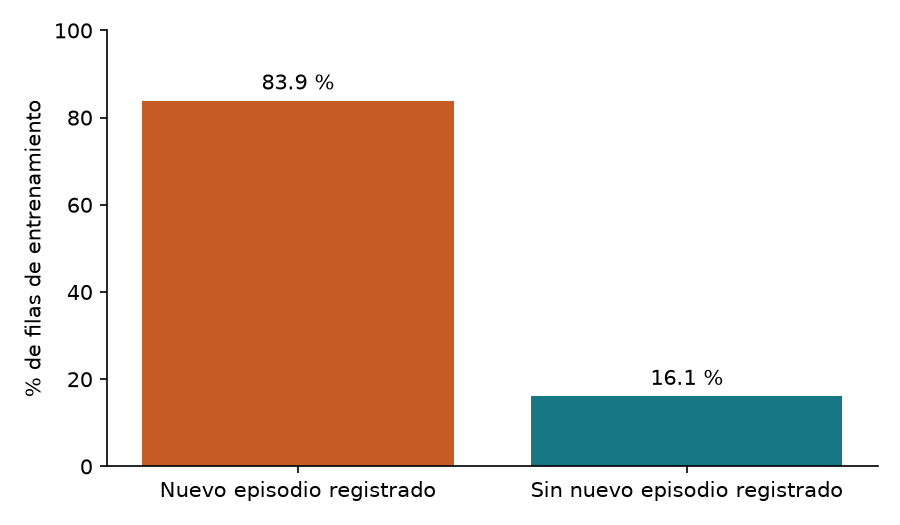

Las ausencias son de registro, no observaciones confirmadas sin fuego.


In [3]:
p=data['training_target_prevalence']
fig,ax=plt.subplots(figsize=(6,3.5))
bars=ax.bar(['Nuevo episodio registrado','Sin nuevo episodio registrado'],[100*p,100*(1-p)],color=['#c45c24','#177785'])
ax.set_ylabel('% de filas de entrenamiento')
ax.set_ylim(0,100)
ax.bar_label(bars,fmt='%.1f %%',padding=3)
ax.spines[['top','right']].set_visible(False)
fig.tight_layout()
figure_folder=repo.parent.parent/'outputs/37_dataset_riesgo_regional/figures'
figure_folder.mkdir(parents=True,exist_ok=True)
figure=figure_folder/'training_label_prevalence.png'
fig.savefig(figure,dpi=150)
plt.close(fig)
display(Image(filename=str(figure)))
print('Las ausencias son de registro, no observaciones confirmadas sin fuego.')

## 3. External evidence and limits of the label
The teammate's events and the official record are used for comparison.
Their matches and disagreements are not invented human labels.
The NOAA-20 non-vegetation mask was frozen before 2018-04-16.

In [4]:
print('Piloto 2013: candidatos enlazados con compañero:',evidence['companion_matched'])
print('Candidatos en eventos iniciados >5 días antes:',evidence['companion_event_over_5d_earlier'])
print('Celdas no vegetales conocidas previamente:',evidence['prior_nonvegetation_cells'])
print('Asociación INDECI:',evidence['registry_associations']['INDECI_shift_0'])
print('Máscara congelada para NOAA-20:',reference['frozen_nonvegetation_mask'])
print('Revisión humana de ignición terminada:',evidence['human_review_complete'])
display(Markdown('**Una coincidencia no demuestra ignición; una ausencia de coincidencia no demuestra un falso incendio.**'))

Piloto 2013: candidatos enlazados con compañero: 32785
Candidatos en eventos iniciados >5 días antes: 1044
Celdas no vegetales conocidas previamente: 184
Asociación INDECI: {'references': 68, 'candidate_matches': 46, 'candidate_fraction': 0.0013915358320476753}
Máscara congelada para NOAA-20: {'enabled': True, 'cutoff': '2018-04-16 05:00:00+00:00', 'known_source_cells': 2892, 'excluded_detections': 3317, 'rule': 'type 1/2/3 observed before cutoff in a rounded 0.005 degree cell; no full-history persistence rule'}
Revisión humana de ignición terminada: False


**Una coincidencia no demuestra ignición; una ausencia de coincidencia no demuestra un falso incendio.**

## 4. Weather and NRT: preparation versus real availability
The weather is a point sample per region and uses past observations,
not realized future weather. The historical delays are explicit
assumptions: publications and reanalysis versions were not reconstructed.
NRT ingestion was done once from the ZIP files; there is no automatic refresh yet.

In [5]:
print('Retardo supuesto de referencia:',protocol['reference_feature_delay_days_assumed'],'días')
print('Retardo meteorológico supuesto tras fin del día:',protocol['weather_release_delay_days_assumed_after_day_end'],'días')
print('Disponibilidad histórica verificada:',data['historical_available_at_verified'])
print('Meteorología:',data['weather_spatial_support'])
print('NRT elegibles:',nrt['eligible_rows'])
print('Última adquisición NRT:',nrt['last_acquisition_utc'])
print('NRT sin campo type:',nrt['type_unavailable_rows'])
print('Transferencia NRT/SP validada:',nrt['NRT_SP_transfer_validated'])
print('Refresco automático configurado:',nrt['automatic_FIRMS_refresh_configured'])

Retardo supuesto de referencia: 3 días
Retardo meteorológico supuesto tras fin del día: 7 días
Disponibilidad histórica verificada: False
Meteorología: representative point per department, not areal mean
NRT elegibles: 40384
Última adquisición NRT: 2026-11-13T18:47:00+00:00
NRT sin campo type: 40384
Transferencia NRT/SP validada: False
Refresco automático configurado: False


## 5. Next review point: experimental training
We will compare regional/seasonal climatology, a simple model and LightGBM.
Fitting, selection, calibration and evaluation will be separate. We will measure Brier,
calibration and precision/recall per lead time and region.
The percentages will first describe detected episodes: before presenting them
as a physical ignition risk, label validation is needed.
Workflow progress: 45 % by deliverables; the published API stays the same.

In [6]:
assert not data['public_api_modified']
assert protocol['new_model_trained'] is False
display(Markdown('**Listo para revisar el dataset experimental. Sin entrenamiento ni nueva API publicados.**'))

**Listo para revisar el dataset experimental. Sin entrenamiento ni nueva API publicados.**